# Day 37 | Return Tool Results to the Model

**KGP Talkie**

Follow the request, execute, result, and final-answer loop.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

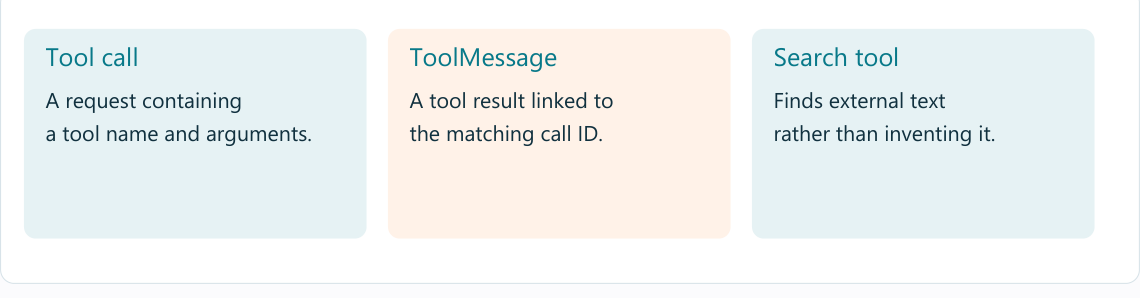

@tool wraps a documented function and exposes its input types as a tool schema.

In [4]:
from langchain_core.tools import tool

The model sees a name, description, and two integer inputs. Python computes the sum.

In [5]:
@tool
def add_numbers(a: int, b: int) -> int:
    """Add two integer numbers and return their exact sum."""
    return a + b

In [6]:
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integer numbers and return their exact product."""
    return a * b

In [7]:
print(add_numbers.name)
print(add_numbers.args)

add_numbers
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}


Test the function directly before a model is allowed to request it.

In [8]:
add_numbers.invoke({"a": 7, "b": 5})

12

ChatOllama sends chat requests to the local Ollama server.

In [9]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [10]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [11]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [12]:
from langchain_core.messages import HumanMessage, ToolMessage

In [13]:
tools_by_name = {"add_numbers": add_numbers, "multiply": multiply}

Binding sends schemas. The next call proposes tools; it does not execute them.

In [14]:
with_tools = llm.bind_tools(list(tools_by_name.values()))

In [15]:
messages = [HumanMessage(content="Use the multiply tool to calculate 6 times 7.")]

In [16]:
reply = with_tools.invoke(messages)
print(reply.tool_calls)

[{'name': 'multiply', 'args': {'a': '6', 'b': '7'}, 'id': '6882d399-d901-469a-a36c-f03f9605cbe4', 'type': 'tool_call'}]


In [17]:
messages.append(reply)

Only allowlisted functions run. Every tool result keeps the matching call ID.

In [18]:
for call in reply.tool_calls:
    if call["name"] not in tools_by_name:
        raise ValueError("Tool is not allowed.")
    value = tools_by_name[call["name"]].invoke(call["args"])
    messages.append(ToolMessage(content=str(value), tool_call_id=call["id"]))

The model now sees the exact computed tool result.

In [19]:
print(llm.invoke(messages).content)

The result of multiplying 6 by 7 is 42.


In [20]:
fresh = with_tools.invoke("Use add_numbers to calculate 8 plus 4.")
print(fresh.tool_calls)

[{'name': 'add_numbers', 'args': {'b': '4', 'a': '8'}, 'id': 'da0b1f5f-54a8-420f-8c47-6407a09e5773', 'type': 'tool_call'}]


## Search providers in the course

| Provider | What it returns | Extra setup |
|---|---|---|
| DuckDuckGo | Web search results | Internet; results can change |
| Tavily | Search text and sources | Internet and an API key |
| Wikipedia | Encyclopedia page text | Internet |
| PubMed | Research article records | Internet |

The model must receive the tool results before writing an evidence-based reply. Our local class tool below searches fixed notes; it is not live web search.

In [21]:
@tool
def search_class_notes(word: str) -> str:
    """Find lines containing a word in the local class timetable."""
    lines = (ASSETS / "course-notes.txt").read_text().splitlines()
    hits = [line for line in lines if word.lower() in line.lower()]
    return "\n".join(hits) if hits else "No matching line."

In [22]:
print(search_class_notes.invoke({"word": "Pandas"}))

Pandas class is on Tuesday at 11:00 in Room 3.


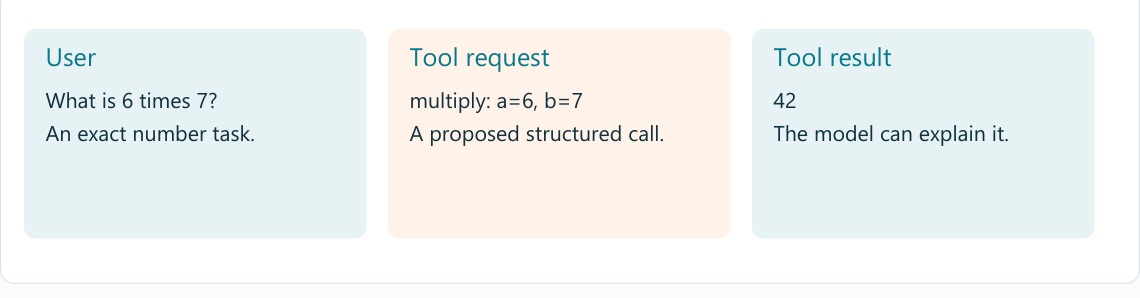

## Try a fresh input

Try a question for a local notes-search tool. The saved notes are not live web results.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-tool-calling).